# Decsion Tree

Decision trees are a model that map out what will predicted outcomes based on "decisions" in the data.


## Loading data

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

df= pd.read_csv("../Data/supermarket_subset.csv")
df.head()


,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00021905,TL00021905,B00037526,C00035108,S00000063,P00001069,E00000401,SUP00000036,44,Female,...,7,15.68,-0.49,-0.219,125,47,0.1,-0.131,0.0720,0.0351
1,T00093977,TL00093977,B00028427,C00062754,S00000076,P00004268,E00000491,SUP00000006,43,Male,...,7,21.77,0.57,0.183,910,21,4.9,-0.063,0.0214,0.0594
2,T00074823,TL00074823,B00049794,C00024688,S00000040,P00000513,E00000418,SUP00000047,46,Female,...,16,96.96,3.03,0.500,754,11,4.5,0.396,0.0479,0.0823
3,T00063004,TL00063004,B00039714,C00093668,S00000032,P00004501,E00000230,SUP00000048,43,Female,...,5,27.85,-1.49,-0.268,495,10,6.1,0.218,0.0000,0.0763
4,T00054231,TL00054231,B00046502,C00038252,S00000021,P00001089,E00000478,SUP00000023,62,Other,...,9,149.31,9.23,0.556,441,44,3.0,-0.272,0.0358,0.0710


preparing features

In [25]:
features = ["customer_visit_frequency",
    "average_monthly_visits",
    "average_transaction_value",
    "product_category",
    "brand",
    "selling_price",
    "promotion_active",
    "coupon_used",
    "mobile_app_notification",
    "day_of_week",
    "shopping_period",
    "shopping_duration_minutes",]

target = 'repeat_purchase'

X = pd.get_dummies(df[features], drop_first=True)
y = df[target]

x_train, x_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=40) #splitting data for training

x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=40) #splitting data for validation and testing

print("training:", len(x_train), "validation:", len(x_val), "test:", len(x_test))

training: 8400 validation: 1800 test: 1800


## Training Data

the classifier makes categories that make predictions based on true/false or yes/no answers. low depth levels make overfitting less likely

In [26]:
model = DecisionTreeClassifier(max_depth=4, random_state=40)
model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",40
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

## Evalute

The evaluation shows how well the model performs on this data.

In [27]:
y_pred = model.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.5716666666666667
              precision    recall  f1-score   support

          No       0.71      0.01      0.01       774
         Yes       0.57      1.00      0.73      1026

    accuracy                           0.57      1800
   macro avg       0.64      0.50      0.37      1800
weighted avg       0.63      0.57      0.42      1800



## visualization

Shows how the tree looks in a model.

<function matplotlib.pyplot.show(close=None, block=None)>

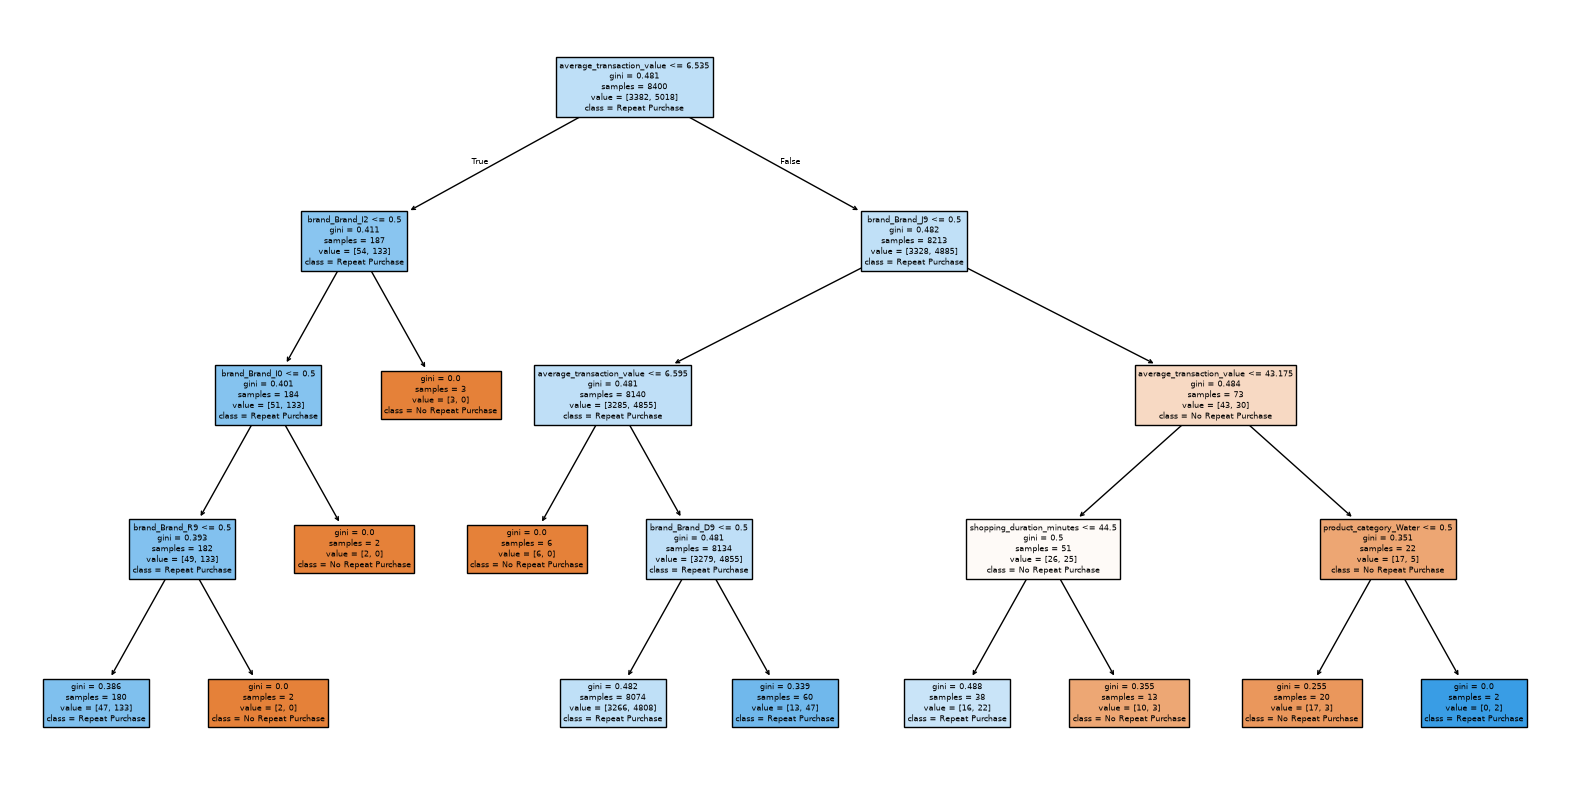

In [28]:
plt.figure(figsize=(20,10))
plot_tree(model, feature_names=X.columns, class_names=['No Repeat Purchase', 'Repeat Purchase'], filled=True)
plt.show